# DCR residuals of Gaia white dwarfs (paper \todo in the Discussion)

White dwarfs have spectra unlike the main-sequence stars the DCR model was fitted to (pressure-broadened Balmer lines,
no metal lines). Do their positions carry a DCR residual at fixed colour? Gaia white dwarfs among our clean Gaia stars:
Gaia parallax S/N > 5 and M_G > 10 + 2.5 (BP-RP) (below the main sequence; a simple version of the usual Gaia
white-dwarf cut). Offsets along the parallactic direction after the two-line DCR correction (`par_dcr`) per unit
tan z, vs relative colour, compared with all other clean Gaia stars at the same colour. Internal figure.

In [1]:
import os, sys
import numpy as np
import fitsio
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
from py_files.pm_analysis import COMBINED_DIR
ps.apply()
dcr_fit.ccd_reference_colour()   # load once before forking
CACHE = os.path.join(COMBINED_DIR, 'wd_dcr_sample.npz')

def one(d):
    fo = os.path.join(COMBINED_DIR, f'gaia-objects-{d}.fits')
    if not os.path.exists(fo):
        return None
    T = fitsio.read(fo, columns=['brickid', 'objid', 'parallax', 'parallax_ivar', 'gaia_phot_g_mean_mag',
                                 'gaia_phot_bp_mean_mag', 'gaia_phot_rp_mean_mag'])
    with np.errstate(all='ignore'):
        snr = T['parallax'] * np.sqrt(T['parallax_ivar'])
        MG = T['gaia_phot_g_mean_mag'] + 5 * np.log10(T['parallax'] / 100.)
        bprp = T['gaia_phot_bp_mean_mag'] - T['gaia_phot_rp_mean_mag']
    wd = (snr > 5) & (MG > 10 + 2.5 * bprp) & (bprp > -0.6) & (bprp != 0)
    wk = np.sort((T['brickid'][wd].astype(np.int64) << 32) | T['objid'][wd].astype(np.int64))
    S = dcr_fit.load_stage_sample([d], brick_fraction=1.0)
    sk = (S['brickid'].astype(np.int64) << 32) | S['objid'].astype(np.int64)
    is_wd = np.isin(sk, wk)
    m = S['clean'] & np.isfinite(S['c_rel']) & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3)
    rng = np.random.default_rng(int(d))
    keep = m & (is_wd | (rng.random(len(sk)) < 0.1))   # all white-dwarf epochs, 10% of the others
    return {'band': S['band'][keep], 'c_rel': S['c_rel'][keep].astype(np.float32), 'tanz': S['tanz'][keep].astype(np.float32),
            'par_dcr': S['par_dcr'][keep].astype(np.float32), 'par_raw': S['par_raw'][keep].astype(np.float32),
            'wd': is_wd[keep], 'key': sk[keep]}

if os.path.exists(CACHE):
    W = dict(np.load(CACHE))
else:
    with ProcessPoolExecutor(16, mp_context=mp.get_context('fork')) as ex:
        parts = [p for p in ex.map(one, [f'{d:03d}' for d in range(64)]) if p is not None]
    W = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    np.savez(CACHE, **W)
print(f"white dwarfs: {len(np.unique(W['key'][W['wd']])):,} stars, {W['wd'].sum():,} epochs (tan z 0.3-1.3); comparison epochs {(~W['wd']).sum():,}")

white dwarfs: 18,626 stars, 409,745 epochs (tan z 0.3-1.3); comparison epochs 22,351,759


g other Gaia stars c_rel -2.13: residual -68.63 +- 0.98 mas per tan z
g other Gaia stars c_rel -1.85: residual -11.86 +- 0.44 mas per tan z
g other Gaia stars c_rel -1.58: residual  -2.65 +- 0.23 mas per tan z
g other Gaia stars c_rel -1.33: residual  -0.22 +- 0.09 mas per tan z
g other Gaia stars c_rel -1.10: residual  -1.81 +- 0.05 mas per tan z
g other Gaia stars c_rel -0.87: residual  -2.26 +- 0.03 mas per tan z
g other Gaia stars c_rel -0.63: residual  -1.01 +- 0.03 mas per tan z
g other Gaia stars c_rel -0.38: residual  -0.26 +- 0.03 mas per tan z
g other Gaia stars c_rel -0.12: residual  -0.25 +- 0.03 mas per tan z
g other Gaia stars c_rel +0.11: residual  -0.16 +- 0.04 mas per tan z
g other Gaia stars c_rel +0.37: residual  -0.13 +- 0.04 mas per tan z
g other Gaia stars c_rel +0.63: residual  -0.07 +- 0.04 mas per tan z
g other Gaia stars c_rel +0.88: residual  -0.09 +- 0.04 mas per tan z
g other Gaia stars c_rel +1.27: residual  -0.26 +- 0.03 mas per tan z
g white dwarfs     c

r other Gaia stars c_rel -2.14: residual -15.30 +- 0.48 mas per tan z
r other Gaia stars c_rel -1.84: residual  -3.79 +- 0.30 mas per tan z
r other Gaia stars c_rel -1.57: residual  -0.98 +- 0.13 mas per tan z
r other Gaia stars c_rel -1.34: residual  +0.47 +- 0.05 mas per tan z
r other Gaia stars c_rel -1.10: residual  +0.75 +- 0.03 mas per tan z
r other Gaia stars c_rel -0.87: residual  +0.32 +- 0.02 mas per tan z
r other Gaia stars c_rel -0.63: residual  +0.12 +- 0.02 mas per tan z
r other Gaia stars c_rel -0.38: residual  +0.14 +- 0.03 mas per tan z
r other Gaia stars c_rel -0.11: residual  +0.69 +- 0.02 mas per tan z
r other Gaia stars c_rel +0.11: residual  +0.38 +- 0.03 mas per tan z
r other Gaia stars c_rel +0.38: residual  -0.08 +- 0.03 mas per tan z
r other Gaia stars c_rel +0.63: residual  -0.02 +- 0.03 mas per tan z
r other Gaia stars c_rel +0.88: residual  +0.08 +- 0.03 mas per tan z
r other Gaia stars c_rel +1.33: residual  +0.36 +- 0.02 mas per tan z
r white dwarfs     c

i other Gaia stars c_rel -2.12: residual  -7.65 +- 0.65 mas per tan z
i other Gaia stars c_rel -1.84: residual  +0.57 +- 0.36 mas per tan z
i other Gaia stars c_rel -1.57: residual  +0.70 +- 0.15 mas per tan z
i other Gaia stars c_rel -1.33: residual  +0.73 +- 0.06 mas per tan z
i other Gaia stars c_rel -1.10: residual  +1.00 +- 0.03 mas per tan z
i other Gaia stars c_rel -0.87: residual  +0.63 +- 0.03 mas per tan z
i other Gaia stars c_rel -0.63: residual  +0.36 +- 0.03 mas per tan z
i other Gaia stars c_rel -0.38: residual  +0.21 +- 0.03 mas per tan z
i other Gaia stars c_rel -0.11: residual  +0.21 +- 0.03 mas per tan z
i other Gaia stars c_rel +0.11: residual  +0.08 +- 0.03 mas per tan z
i other Gaia stars c_rel +0.38: residual  +0.10 +- 0.03 mas per tan z
i other Gaia stars c_rel +0.63: residual  +0.07 +- 0.03 mas per tan z
i other Gaia stars c_rel +0.88: residual  +0.08 +- 0.03 mas per tan z
i other Gaia stars c_rel +1.37: residual  +0.21 +- 0.01 mas per tan z
i white dwarfs     c

z other Gaia stars c_rel -2.32: residual  -2.30 +- 0.63 mas per tan z
z other Gaia stars c_rel -1.83: residual  +1.60 +- 0.39 mas per tan z
z other Gaia stars c_rel -1.58: residual  +0.94 +- 0.18 mas per tan z
z other Gaia stars c_rel -1.33: residual  +0.67 +- 0.08 mas per tan z
z other Gaia stars c_rel -1.09: residual  +0.89 +- 0.04 mas per tan z
z other Gaia stars c_rel -0.87: residual  +0.72 +- 0.03 mas per tan z
z other Gaia stars c_rel -0.63: residual  +0.60 +- 0.03 mas per tan z
z other Gaia stars c_rel -0.38: residual  +0.44 +- 0.03 mas per tan z
z other Gaia stars c_rel -0.12: residual  +0.28 +- 0.03 mas per tan z
z other Gaia stars c_rel +0.12: residual  +0.25 +- 0.03 mas per tan z
z other Gaia stars c_rel +0.38: residual  +0.25 +- 0.03 mas per tan z
z other Gaia stars c_rel +0.63: residual  +0.19 +- 0.03 mas per tan z
z other Gaia stars c_rel +0.88: residual  +0.13 +- 0.02 mas per tan z
z other Gaia stars c_rel +1.37: residual  +0.16 +- 0.01 mas per tan z
z white dwarfs     c

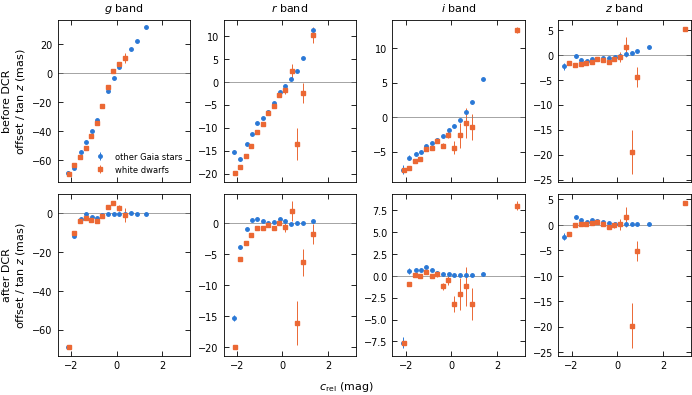

In [2]:
C_EDGES = np.linspace(-2.0, 1.0, 13)
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 4.0), sharex=True, layout='constrained')
for row, stage in enumerate(['raw', 'dcr']):
    for ax, band in zip(axes[row], 'griz'):
        for k, (lab, sel) in enumerate([('other Gaia stars', ~W['wd']), ('white dwarfs', W['wd'])]):
            q = sel & (W['band'] == band)
            cells = dcr_fit.binned_2d(W['c_rel'][q], W['tanz'][q], W[f'par_{stage}'][q], C_EDGES, np.array([0.3, 1.3]), min_count=100)
            if len(cells):
                ax.errorbar(cells[0] + 0.02 * k, cells[2] / cells[1], cells[3] / cells[1], fmt=ps.MARKERS[k], ms=2.5, lw=0.7,
                            color=ps.SERIES[k], label=lab)
                if stage == 'dcr':
                    for c_, y_, e_ in zip(cells[0], cells[2] / cells[1], cells[3] / cells[1]):
                        print(f'{band} {lab:16s} c_rel {c_:+.2f}: residual {y_:+6.2f} +- {e_:.2f} mas per tan z')
        ax.axhline(0, color='0.5', lw=0.5)
        if row == 0:
            ax.set_title(f'${band}$ band')
    axes[row, 0].set_ylabel(('before DCR' if stage == 'raw' else 'after DCR') + '\noffset / tan $z$ (mas)')
axes[0, 0].legend(fontsize=6)
fig.supxlabel(r'$c_{\rm rel}$ (mag)', fontsize=8)
plt.savefig('plots/wd_dcr.pdf')